# SafeXTrail risk model - Telescope Peak (Death Valley NP)

This notebook builds the **risk score + explanation** that the Orchestrate `score_risk` tool serves.
It follows the data flow in your diagram, box 2 (weather agent + machine learning + trained model).

| Step | What happens | Output |
|---|---|---|
| 1 | Scrape NPS Morning Reports | raw entries |
| 2 | Filter and structure Telescope-area hiker incidents | incident table |
| 3 | (optional) NPS mortality context | cause mix |
| 4 | Pull ~35 years of daily weather for valley floor + summit | feature table |
| 5 | Label each weather-day: incident that day = 1, else 0 | training set |
| 6 | Train a regularized logistic regression, validate leave-one-incident-out | coefficients |
| 7 | Export coefficients + incident list | JSON files |
| 8 | Sync into the Orchestrate tools | tool files |
| 9 | Try scenarios and read the explanation | sanity check |

**DEMO mode** (`SAFEXTRAIL_DEMO=1`) runs offline: it uses the bundled sample entries and **synthetic weather**.
Demo results are meaningless as science and are written to `*_demo.json` so they never overwrite real output.
For real results leave `SAFEXTRAIL_DEMO` unset (needs internet).

In [42]:
%pip install numpy pandas matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [43]:
IMG_DIR = ROOT / "diagrams"
IMG_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(fig, filename):
    out_path = IMG_DIR / filename
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    print(f"Saved: {out_path}")


In [44]:
import os, sys, json, subprocess
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from scrapers import morning_report, incident_structuring, weather
from risk_engine import engine

DEMO = os.environ.get("SAFEXTRAIL_DEMO", "0") == "1"
SMOOTH_DAYS = 0      # label +/- this many days around each incident (use 1 if dates feel unreliable)
print("DEMO mode:", DEMO, "| project root:", ROOT)

DEMO mode: False | project root: /home/sapikachu/IBM/ML-Analysis/safextrail


## Step 1 - Scrape the Morning Reports
`morning_report.load_entries()` downloads the Death Valley incident page once, caches it in `data/raw/deva.html`,
and splits it into one record per report (date, case id, headline, narrative). Re-runs use the cache.
**Check the entry count**: a live run should show hundreds of entries. If it shows 0, open the cached HTML and adjust
`ENTRY_RE` in `scrapers/morning_report.py`.

In [45]:
if DEMO:
    entries = morning_report.parse_entries((ROOT / "tests/fixtures/deva_sample.txt").read_text())
else:
    entries = morning_report.load_entries()
print(len(entries), "entries;", entries[0].report_date, "to", entries[-1].report_date)

139 entries; 1987-08-26 to 2002-09-09


## Step 2 - Filter and structure incidents
Rules in `scrapers/incident_structuring.py`: group follow-ups by case id, drop vehicle/fire/crime reports, **drop suicides
(counted but never kept)**, keep only Telescope-area text, then extract incident date, zone, cause, outcome, temperature, elevation.
Only derived fields survive - no narratives or initials. **Spot-check 10-20 rows against the source page** before trusting them.
`date_confidence = low` means no date was found in the text and we guessed (report date minus 3 days).

In [46]:
res = incident_structuring.structure(entries)
incidents = pd.DataFrame(res["incidents"])
print(res["stats"])
display(incidents[["case_id", "incident_date", "date_confidence", "zone", "cause", "outcome", "temp_f"]])

{'entries': 139, 'cases': 120, 'non_hiker': 83, 'sensitive_excluded': 12, 'outside_area': 19, 'kept': 6}


,case_id,incident_date,date_confidence,zone,cause,outcome,temp_f
0,88-68,1988-04-30,narrative,wildrose_peak,lost,unknown,30.0
1,88-103,1988-06-11,low,badwater_route,dehydration,rescued,NaN
2,91-323,1991-07-21,narrative,badwater_route,heat,fatal,120.0
3,94-454,1994-08-06,narrative,telescope_trail,unknown,fatal,NaN
4,97-776,1998-01-04,narrative,jail_canyon,lost,rescued,NaN
5,98-682,1998-10-12,narrative,dantes_view_route,dehydration,rescued,NaN


## Step 3 (optional) - NPS mortality context
Download the Excel file linked at nps.gov/aboutus/mortality-data.htm into `data/raw/`. It is used to sanity-check the cause mix
(heat vs. falls vs. medical), **not** as model labels: it has no weather and mixes in every kind of death in the park.

In [47]:
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.


In [48]:
xlsx = sorted((ROOT / "data" / "raw").glob("*ortality*.xlsx"))
if xlsx:
    from scrapers import nps_mortality
    display(nps_mortality.death_valley_summary(nps_mortality.load(xlsx[-1])))
else:
    print("No NPS mortality workbook in data/raw/ - skipping (optional).")

Columns found: {'park': 'Park Name', 'date': 'Incident Date', 'cause': 'Cause of Death', 'intent': 'Intent'}


,deaths
Cause of Death,
Motor Vehicle Crash,21
Hyperthermia,11
Fall,7
Drowning,1
Poisoning - drugs,1
Hypothermia,1
Asphyxiation,1


## Step 4 - Daily weather history for the two sites
The model sees the same five daily features that `get_forecast` computes live: valley-floor feels-like max (heat), and summit
feels-like min, gust max, snowfall and precipitation (cold/wind/snow). Open-Meteo is downscaled to each site's real elevation.

In [49]:
def make_demo_weather(start="1987-01-01", end="2002-12-31", seed=0):
    # SYNTHETIC - only so the notebook runs offline. Seasonal sine waves plus noise.
    rng = np.random.default_rng(seed)
    d = pd.date_range(start, end, freq="D"); n = len(d)
    season = np.sin(2 * np.pi * (d.dayofyear.values - 110) / 365.25)      # +1 near late July
    p_snow = 0.12 * (1 - season) / 2
    return pd.DataFrame({
        "valley_feels_max_c": 31 + 17 * season + rng.normal(0, 3, n),
        "summit_feels_min_c": -2 + 13 * season + rng.normal(0, 4, n),
        "summit_gust_max_kph": np.clip(38 - 8 * season + rng.gamma(2, 8, n) - 16, 0, None),
        "summit_snow_cm": np.where(rng.random(n) < p_snow, rng.exponential(6, n), 0.0),
        "precip_mm": np.where(rng.random(n) < 0.07, rng.exponential(4, n), 0.0)}, index=d)

if DEMO:
    X = make_demo_weather()
else:
    end = (pd.Timestamp.today() - pd.Timedelta(days=10)).strftime("%Y-%m-%d")
    X = weather.build_feature_frame("1988-01-01", end)
X = X[list(engine.FEATURES)]
print(len(X), "days", X.index.min().date(), "to", X.index.max().date())
display(X.describe().round(1))

14193 days 1988-01-01 to 2026-11-09


,valley_feels_max_c,summit_feels_min_c,summit_gust_max_kph,summit_snow_cm,precip_mm
count,14193.0,14193.0,14193.0,14193.0,14193.0
mean,29.9,-5.2,38.9,0.1,0.5
std,11.4,8.2,16.9,0.6,2.4
min,-2.8,-29.1,11.5,0.0,0.0
25%,19.8,-11.7,26.6,0.0,0.0
50%,30.0,-5.8,36.0,0.0,0.0
75%,40.1,2.0,47.9,0.0,0.0
max,54.2,15.1,169.9,27.6,110.1


Saved: /home/sapikachu/IBM/ML-Analysis/safextrail/diagrams/01_feature_correlation.png


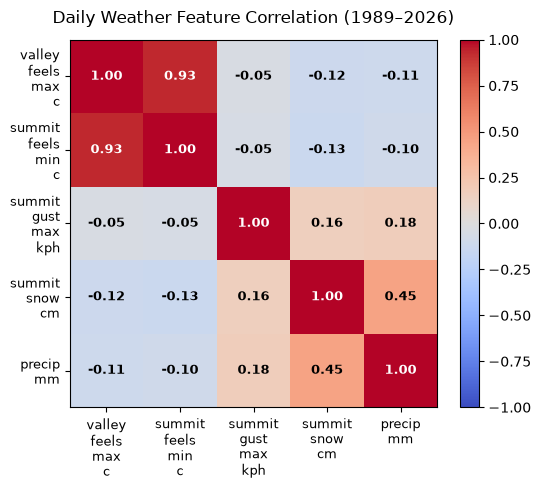

In [50]:
corr = X.corr()

fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

labels = [c.replace("_", "\n") for c in corr.columns]
ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, fontsize=9)
ax.set_yticklabels(labels, fontsize=9)

for i in range(len(corr)):
    for j in range(len(corr)):
        val = corr.iloc[i, j]
        color = "white" if abs(val) > 0.55 else "black"
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", color=color, fontsize=9, fontweight="bold")

ax.set_title("Daily Weather Feature Correlation (1989–2026)", pad=12)
plt.tight_layout()
save_fig(fig, "01_feature_correlation.png")
plt.show()


## Step 5 - Label each weather-day
**Why this design?** The Morning Reports only list incidents; they never say how many hikers were out and fine. So we build a
*denominator from the calendar*: every day is a row, and a day is `1` if a Telescope-area incident started that day, else `0`.
The model therefore learns **which weather is over-represented on incident days** - a *relative hazard*, not an absolute
probability. Expect very few positives, so keep the model simple.

In [51]:
inc_days = pd.to_datetime(incidents["incident_date"])
if SMOOTH_DAYS:
    inc_days = pd.DatetimeIndex(sorted({d + pd.Timedelta(days=k) for d in inc_days for k in range(-SMOOTH_DAYS, SMOOTH_DAYS + 1)}))
y = X.index.isin(inc_days).astype(int)
n_incidents = int(incidents.index.size)
print("positive days:", int(y.sum()), "of", len(y), "| distinct incidents:", n_incidents,
      "| incidents outside weather range:", int((~inc_days.isin(X.index)).sum()))
assert y.sum() >= 3, "Too few positive days to fit a model - check Steps 1-2."

positive days: 6 of 14193 | distinct incidents: 6 | incidents outside weather range: 0


Saved: /home/sapikachu/IBM/ML-Analysis/safextrail/diagrams/02_incident_weather_anomalies.png


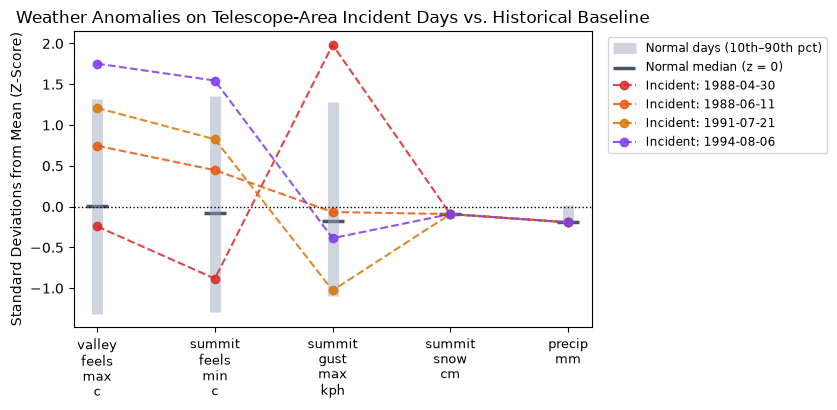

In [52]:
Z_df = (X - X.mean()) / X.std(ddof=0)
inc_dates = X.index[y == 1]

fig, ax = plt.subplots(figsize=(8.5, 4.2))
positions = np.arange(len(X.columns))

# Background distribution (10th to 90th percentile + median of normal days)
normal_z = Z_df[y == 0]
q10, q50, q90 = normal_z.quantile(0.10), normal_z.quantile(0.50), normal_z.quantile(0.90)
ax.vlines(positions, q10, q90, color="#94a3b8", linewidth=8, alpha=0.45, label="Normal days (10th–90th pct)")
ax.scatter(positions, q50, color="#475569", marker="_", s=250, linewidths=2.5, label="Normal median (z = 0)")

# Plot each individual incident day
colors = ["#dc2626", "#ea580c", "#d97706", "#7c3aed"]
for idx, (dt, col) in enumerate(zip(inc_dates, colors)):
    vals = Z_df.loc[dt].values
    ax.plot(positions, vals, marker="o", linestyle="--", alpha=0.85, color=col, label=f"Incident: {dt.strftime('%Y-%m-%d')}")

ax.axhline(0, color="black", linestyle=":", linewidth=1)
ax.set_xticks(positions)
ax.set_xticklabels([c.replace("_", "\n") for c in X.columns], fontsize=9)
ax.set_ylabel("Standard Deviations from Mean (Z-Score)")
ax.set_title("Weather Anomalies on Telescope-Area Incident Days vs. Historical Baseline")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8.5)
plt.tight_layout()
save_fig(fig, "02_incident_weather_anomalies.png")
plt.show()



## Step 6 - Train and validate
With only a handful of incidents, a plain fit can learn nonsense (we saw hotter weather *lowering* risk in demo mode). So the fit has guard-rails:
* Features are standardized (z-scores) so each factor's contribution is exactly `coef * z`.
* `LogisticRegression` with strong L2 regularization (`C=0.1`) and `class_weight="balanced"` (we only use the *ranking* of days).
* **Sign constraints:** any feature whose learned sign contradicts physics (hotter valley, colder summit, more wind or snow = riskier) is dropped and the model is refit.
* **Shrinkage toward expert priors:** `final = w * learned + (1 - w) * prior`, with `w = n_incidents / (n_incidents + 15)`. Few incidents, so priors dominate; more incidents let the data speak.
* **Leave-one-incident-out validation** of this whole procedure: retrain without one incident day and see where it ranks among normal days. 0.5 = chance, 1.0 = perfect. With a handful of incidents this is a smoke test, not proof.

In [53]:
SHRINK_K = 15
means, stds = X.mean(), X.std(ddof=0)
Z = ((X - means) / stds).values
FEATS = list(engine.FEATURES)
prior = np.array([engine.PRIOR_COEFS[f] for f in FEATS])

def train(Zm, ym):
    active = list(range(len(FEATS)))
    while active:
        m = LogisticRegression(C=0.1, class_weight="balanced", max_iter=2000).fit(Zm[:, active], ym)
        bad = [a for a, c in zip(active, m.coef_[0]) if np.sign(c) != engine.EXPECTED_SIGN[FEATS[a]]]
        if not bad:
            break
        active.remove(max(bad, key=lambda a: abs(m.coef_[0][active.index(a)])))   # drop worst offender, refit
    learned = np.zeros(len(FEATS))
    if active:
        learned[active] = m.coef_[0]
    w = ym.sum() / (ym.sum() + SHRINK_K)
    return w * learned + (1 - w) * prior, learned, w

final, learned, w = train(Z, y)
ranks = []
for i in np.where(y == 1)[0]:
    keep = np.ones(len(y), bool); keep[i] = False
    c, _, _ = train(Z[keep], y[keep])
    lg = Z @ c
    ranks.append(float((lg[y == 0] < lg[i]).mean()))
print("Leave-one-out percentile of held-out incident days: mean %.2f, min %.2f, max %.2f" % (np.mean(ranks), min(ranks), max(ranks)))
print("Weight on learned coefficients (rest is prior): %.2f" % w)
display(pd.DataFrame({"prior": prior, "learned (sign-constrained)": learned, "final": final}, index=FEATS).round(3))

Leave-one-out percentile of held-out incident days: mean 0.66, min 0.31, max 0.97
Weight on learned coefficients (rest is prior): 0.29


,prior,learned (sign-constrained),final
valley_feels_max_c,0.90,3.092,1.526
summit_feels_min_c,-0.60,-2.723,-1.207
summit_gust_max_kph,0.35,0.062,0.268
summit_snow_cm,0.50,0.000,0.357
precip_mm,0.15,0.427,0.229


Saved: /home/sapikachu/IBM/ML-Analysis/safextrail/diagrams/03_model_coefficients.png


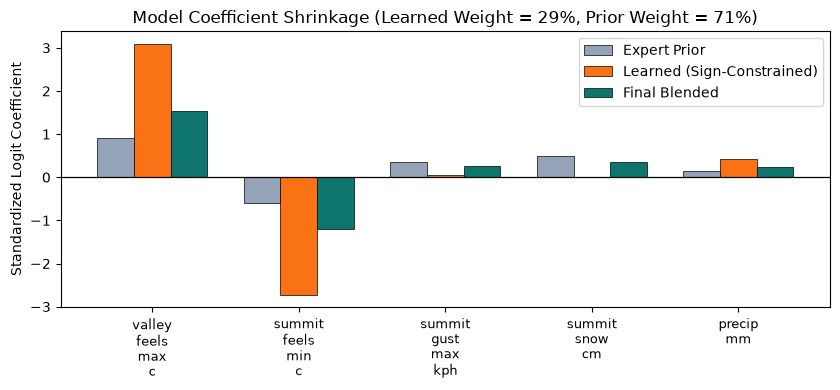

In [54]:
coef_df = pd.DataFrame({
    "Expert Prior": prior,
    "Learned (Sign-Constrained)": learned,
    "Final Blended": final
}, index=[f.replace("_", "\n") for f in FEATS])

ax = coef_df.plot(
    kind="bar",
    figsize=(8.5, 4),
    color=["#94a3b8", "#f97316", "#0f766e"],
    width=0.75,
    edgecolor="black",
    linewidth=0.5
)

ax.axhline(0, color="black", linewidth=0.9)
ax.set_ylabel("Standardized Logit Coefficient")
ax.set_title(f"Model Coefficient Shrinkage (Learned Weight = {w:.0%}, Prior Weight = {1-w:.0%})")
ax.tick_params(axis="x", rotation=0, labelsize=9)
ax.legend(frameon=True)
plt.tight_layout()
save_fig(fig, "03_model_coefficients.png")
plt.show()


## Step 7 - Export coefficients and incidents
The percentile table (101 quantiles of the logit over all training days) is what turns a logit into "worse than X% of historical days".
The incident list (derived fields only) feeds `find_similar_incidents`.

wrote risk_engine/coefficients.json and data/incidents.json
Saved: /home/sapikachu/IBM/ML-Analysis/safextrail/diagrams/04_weather_hazard_logit.png


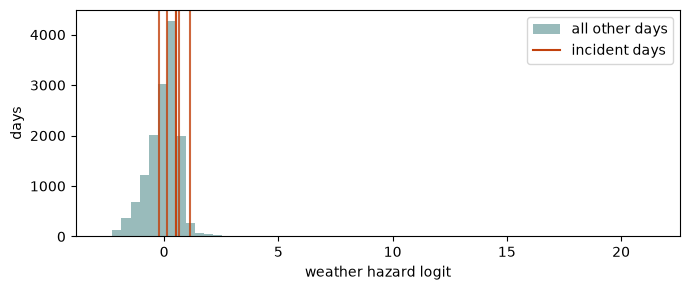

In [55]:
logit_all = Z @ final            # intercept is 0: only the ranking of days matters
coeffs = {
    "is_prior": False, "synthetic": DEMO,
    "n_incidents": n_incidents, "n_days": int(len(y)),
    "trained_on": "%s to %s" % (X.index.min().date(), X.index.max().date()),
    "intercept": 0.0, "learned_weight": float(w),
    "means": {k: float(v) for k, v in means.items()},
    "stds": {k: float(v) for k, v in stds.items()},
    "coefs": {k: float(v) for k, v in zip(FEATS, final)},
    "logit_quantiles": [round(float(q), 4) for q in np.quantile(logit_all, np.linspace(0, 1, 101))],
}
suffix = "_demo" if DEMO else ""
(ROOT / "risk_engine" / f"coefficients{suffix}.json").write_text(json.dumps(coeffs, indent=1))
(ROOT / "data" / f"incidents{suffix}.json").write_text(json.dumps(res["incidents"], indent=1))
print("wrote risk_engine/coefficients%s.json and data/incidents%s.json" % (suffix, suffix))

plt.figure(figsize=(7, 3))
plt.hist(logit_all[y == 0], bins=60, color="#9bb", label="all other days")
for v in logit_all[y == 1]:
    plt.axvline(v, color="#c2410c", alpha=.8)
plt.axvline(np.nan, color="#c2410c", label="incident days")
plt.xlabel("weather hazard logit"); plt.ylabel("days"); plt.legend(); plt.tight_layout();
save_fig(plt.gcf(), "04_weather_hazard_logit.png")
plt.show()

/tmp/ipykernel_5582/1795255972.py:2: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  doy_group = X.groupby(X.index.dayofyear)
/tmp/ipykernel_5582/1795255972.py:28: Pandas4Warning: Timestamp.dayofyear is deprecated and will be removed in a future version. Use Timestamp.day_of_year instead.
  d_year = dt.dayofyear


Saved: /home/sapikachu/IBM/ML-Analysis/safextrail/diagrams/05_seasonal_incidents.png


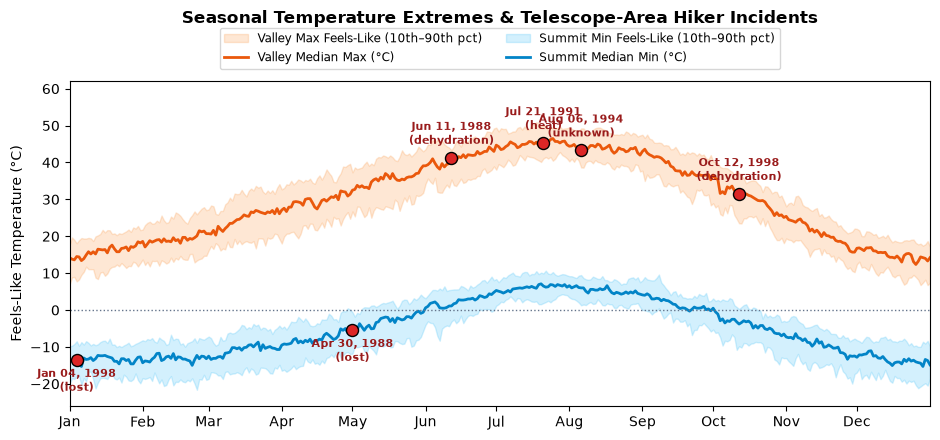

In [58]:
# Compute daily seasonal climatology (10th-90th percentile across all years)
doy_group = X.groupby(X.index.dayofyear)
doy = np.arange(1, 367)

v_med = doy_group["valley_feels_max_c"].median()
v_q10 = doy_group["valley_feels_max_c"].quantile(0.10)
v_q90 = doy_group["valley_feels_max_c"].quantile(0.90)

s_med = doy_group["summit_feels_min_c"].median()
s_q10 = doy_group["summit_feels_min_c"].quantile(0.10)
s_q90 = doy_group["summit_feels_min_c"].quantile(0.90)

fig, ax = plt.subplots(figsize=(9.5, 4.5))

# Valley floor heat band
ax.fill_between(v_med.index, v_q10, v_q90, color="#fb923c", alpha=0.22, label="Valley Max Feels-Like (10th–90th pct)")
ax.plot(v_med.index, v_med, color="#ea580c", linewidth=2, label="Valley Median Max (°C)")

# Summit cold band
ax.fill_between(s_med.index, s_q10, s_q90, color="#38bdf8", alpha=0.22, label="Summit Min Feels-Like (10th–90th pct)")
ax.plot(s_med.index, s_med, color="#0284c7", linewidth=2, label="Summit Median Min (°C)")
ax.axhline(0, color="#64748b", linestyle=":", linewidth=1)

# Plot all kept incidents by day-of-year
inc_dt = pd.to_datetime(incidents["incident_date"])
for _, row in incidents.iterrows():
    dt = pd.to_datetime(row["incident_date"])
    d_year = dt.dayofyear
    # Place marker on valley curve if warm season, summit curve if cold season
    y_pos = v_med.loc[d_year] if dt.month in [5, 6, 7, 8, 9, 10] else s_med.loc[d_year]
    ax.scatter(d_year, y_pos, color="#dc2626", edgecolor="black", s=75, zorder=5)
    ax.annotate(
        f"{dt.strftime('%b %d, %Y')}\n({row['cause']})",
        (d_year, y_pos),
        textcoords="offset points",
        xytext=(0, 10 if dt.month in [5, 6, 7, 8, 9, 10] else -22),
        ha="center",
        fontsize=8,
        fontweight="bold",
        color="#991b1b"
    )

# Format x-axis as months
month_starts = [1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335]
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
ax.set_xticks(month_starts)
ax.set_xticklabels(month_names)
ax.set_xlim(1, 366)
ax.set_ylim(-26, 62)
ax.set_ylabel("Feels-Like Temperature (°C)")

# Place legend cleanly above the plot area
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=2, frameon=True, fontsize=8.5)
ax.set_title("Seasonal Temperature Extremes & Telescope-Area Hiker Incidents", pad=42, fontweight="bold")

plt.tight_layout()
save_fig(fig, "05_seasonal_incidents.png")
plt.show()


Saved: /home/sapikachu/IBM/ML-Analysis/safextrail/diagrams/06_weather_risk_regime.png


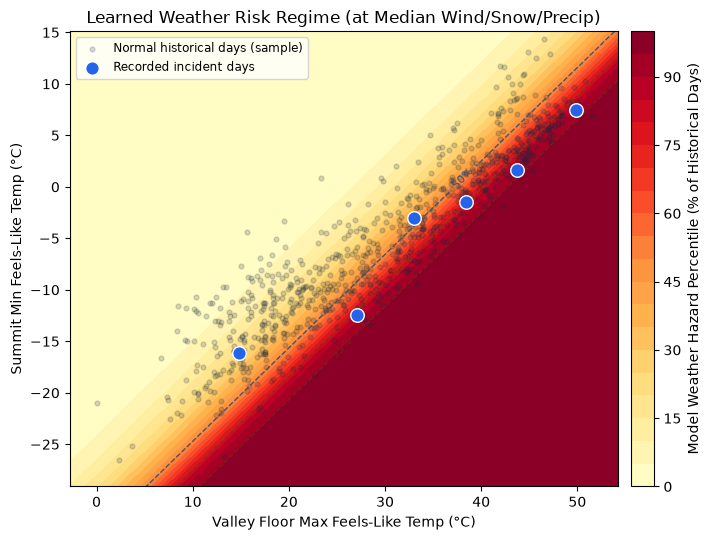

In [59]:
# Create a 2D grid of Valley Heat vs. Summit Cold
v_grid = np.linspace(X["valley_feels_max_c"].min(), X["valley_feels_max_c"].max(), 100)
s_grid = np.linspace(X["summit_feels_min_c"].min(), X["summit_feels_min_c"].max(), 100)
VV, SS = np.meshgrid(v_grid, s_grid)

# Hold wind, snow, and precip at historical medians
med_vals = X.median()
grid_df = pd.DataFrame({
    "valley_feels_max_c": VV.ravel(),
    "summit_feels_min_c": SS.ravel(),
    "summit_gust_max_kph": med_vals["summit_gust_max_kph"],
    "summit_snow_cm": med_vals["summit_snow_cm"],
    "precip_mm": med_vals["precip_mm"],
})[FEATS]

# Compute standardized logit and convert to historical percentile (0 to 100%)
Z_grid = ((grid_df - means) / stds).values
logit_grid = Z_grid @ final
sorted_logits = np.sort(logit_all)
pct_grid = (np.searchsorted(sorted_logits, logit_grid) / len(sorted_logits) * 100).reshape(VV.shape)

fig, ax = plt.subplots(figsize=(7.5, 5.5))
cf = ax.contourf(VV, SS, pct_grid, levels=np.linspace(0, 100, 21), cmap="YlOrRd")
cbar = plt.colorbar(cf, ax=ax, pad=0.02)
cbar.set_label("Model Weather Hazard Percentile (% of Historical Days)")

# Contour lines for 50th, 80th, and 95th risk percentiles
cs = ax.contour(VV, SS, pct_grid, levels=[50, 80, 95], colors=["#475569", "#9a3412", "#7f1d1d"], linestyles="--", linewidths=1)
ax.clabel(cs, inline=True, fontsize=8, fmt="%d%%")

# Scatter sample of normal days + actual incident days in weather range
sample_norm = X[y == 0].sample(min(800, int((y == 0).sum())), random_state=42)
ax.scatter(sample_norm["valley_feels_max_c"], sample_norm["summit_feels_min_c"],
           color="#1e293b", alpha=0.18, s=12, label="Normal historical days (sample)")

inc_in_range = X[y == 1]
ax.scatter(inc_in_range["valley_feels_max_c"], inc_in_range["summit_feels_min_c"],
           color="#2563eb", edgecolor="white", s=95, zorder=6, label="Recorded incident days")

ax.set_xlabel("Valley Floor Max Feels-Like Temp (°C)")
ax.set_ylabel("Summit Min Feels-Like Temp (°C)")
ax.set_title("Learned Weather Risk Regime (at Median Wind/Snow/Precip)")
ax.legend(loc="upper left", fontsize=8.5)
plt.tight_layout()
save_fig(fig, "06_weather_risk_regime.png")
plt.show()


## Step 8 - Sync into the Orchestrate tools
`scripts/sync_tools.py` copies `risk_engine/engine.py`, the coefficients and the incident list into
`orchestrate/tools/score_risk.py` and `find_similar_incidents.py` (tools must be single standalone files).
Skipped in DEMO mode so synthetic coefficients never reach the tools.

In [60]:
if DEMO:
    print("DEMO mode: skipping sync. In a real run this updates the Orchestrate tool files.")
else:
    subprocess.run([sys.executable, "scripts/sync_tools.py"], cwd=ROOT, check=True)

synced: 5 coefficients block, 6 incidents


## Step 9 - Try scenarios and read the explanation
This is exactly what the `score_risk` tool returns. Check that each *why* list is something a ranger would nod at.
Note how elevation shifts the explanation: valley heat matters low, cold/wind/snow matter high.

In [61]:
heat   = dict(valley_feels_max_c=49, summit_feels_min_c=12, summit_gust_max_kph=25, summit_snow_cm=0, precip_mm=0)
storm  = dict(valley_feels_max_c=12, summit_feels_min_c=-18, summit_gust_max_kph=90, summit_snow_cm=15, precip_mm=8)
calm   = dict(valley_feels_max_c=28, summit_feels_min_c=4, summit_gust_max_kph=30, summit_snow_cm=0, precip_mm=0)
scenarios = {
    "Badwater route, extreme heat, overdue 45 min, stationary 60 min":
        (heat, dict(hiker_elevation_m=0, minutes_overdue=45, minutes_stationary=60, minutes_since_fix=10)),
    "Summit ridge, winter storm, 40 min of daylight left":
        (storm, dict(hiker_elevation_m=3300, minutes_since_fix=10, daylight_left_min=40)),
    "Mahogany Flat, calm spring day": (calm, dict(hiker_elevation_m=2500, minutes_since_fix=10, daylight_left_min=300)),
}
for name, (f, s) in scenarios.items():
    r = engine.score(f, s, coeffs)
    print("\n==", name); print(r["summary"]); print("  action:", r["recommended_action"], "| confidence:", r["confidence"])
    for fac in r["factors"]:
        print("   %5.1f pts  %s" % (fac["points"], fac["text"]))


== Badwater route, extreme heat, overdue 45 min, stationary 60 min
HIGH (72/100): Valley floor feels like 49 C (120 F) at its peak; No movement for 60 min; Check-in overdue by 45 min
  action: Message the hiker and put the SAR duty officer on standby. | confidence: 0.7
    54.5 pts  Valley floor feels like 49 C (120 F) at its peak
    10.0 pts  No movement for 60 min
     7.5 pts  Check-in overdue by 45 min

== Summit ridge, winter storm, 40 min of daylight left
HIGH (59/100): 15 cm of snow forecast at the summit; Summit feels as cold as -18 C (0 F); Only 40 min of daylight left
  action: Message the hiker and put the SAR duty officer on standby. | confidence: 0.7
    39.8 pts  15 cm of snow forecast at the summit
     8.3 pts  Summit feels as cold as -18 C (0 F)
     3.9 pts  Only 40 min of daylight left
     3.5 pts  Summit wind gusts up to 90 km/h
     3.2 pts  8 mm of precipitation forecast

== Mahogany Flat, calm spring day
LOW (1/100): Typical seasonal conditions (no single weat

Saved: /home/sapikachu/IBM/ML-Analysis/safextrail/diagrams/07_operational_risk_breakdown.png


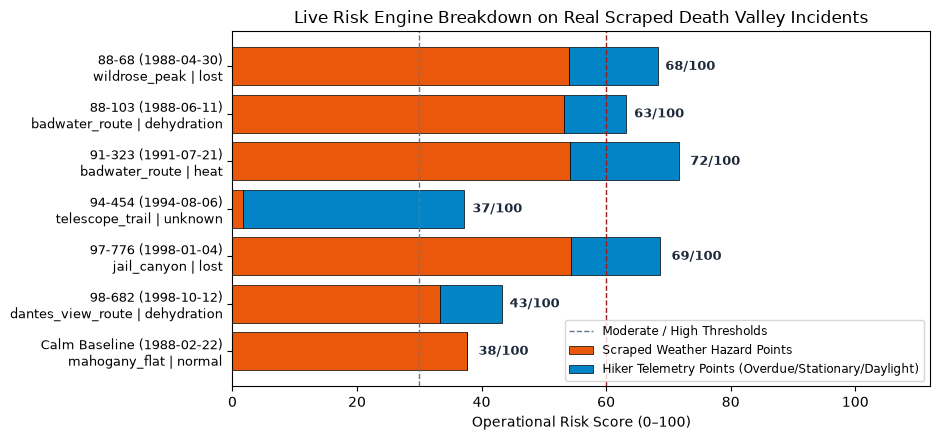

In [62]:
# 1. Match your real scraped incidents with their actual historical weather from X
inc_df = incidents.copy()
inc_df["dt"] = pd.to_datetime(inc_df["incident_date"])
in_range = inc_df[inc_df["dt"].isin(X.index)].copy()

# Realistic SAR telemetry profiles mapped to each incident's scraped cause/outcome
telemetry_by_cause = {
    "heat":        dict(hiker_elevation_m=50,   minutes_overdue=45, minutes_stationary=60, minutes_since_fix=15, daylight_left_min=180),
    "dehydration": dict(hiker_elevation_m=800,  minutes_overdue=30, minutes_stationary=40, minutes_since_fix=10, daylight_left_min=150),
    "lost":        dict(hiker_elevation_m=2800, minutes_overdue=60, minutes_stationary=20, minutes_since_fix=25, daylight_left_min=35),
    "unknown":     dict(hiker_elevation_m=3200, minutes_overdue=90, minutes_stationary=90, minutes_since_fix=30, daylight_left_min=20),
}

# Add one calm baseline day from X for contrast
calm_date = X[(X["valley_feels_max_c"].between(24, 28)) & (X["summit_snow_cm"] == 0) & (X["precip_mm"] == 0)].index[0]
rows_to_score = []

for _, row in in_range.iterrows():
    dt = row["dt"]
    w_dict = X.loc[dt].to_dict()
    telem = telemetry_by_cause.get(row["cause"], telemetry_by_cause["unknown"])
    label = f"{row['case_id']} ({dt.strftime('%Y-%m-%d')})\n{row['zone']} | {row['cause']}"
    rows_to_score.append((label, w_dict, telem))

rows_to_score.append((
    f"Calm Baseline ({calm_date.strftime('%Y-%m-%d')})\nmahogany_flat | normal",
    X.loc[calm_date].to_dict(),
    dict(hiker_elevation_m=2500, minutes_overdue=0, minutes_stationary=0, minutes_since_fix=5, daylight_left_min=300)
))

# 2. Score each scenario using the real engine and separate Weather vs. Telemetry points
weather_keywords = ("valley", "summit", "snow", "precip", "wind", "gust", "seasonal", "cold", "heat")
labels, weather_pts, telem_pts, total_scores, actions = [], [], [], [], []

for label, w_dict, telem in rows_to_score:
    res_score = engine.score(w_dict, telem, coeffs)
    w_sum = sum(f["points"] for f in res_score["factors"] if any(k in f["text"].lower() for k in weather_keywords))
    t_sum = sum(f["points"] for f in res_score["factors"]) - w_sum
    
    labels.append(label)
    weather_pts.append(w_sum)
    telem_pts.append(t_sum)
    # Extract numeric score from summary e.g. "HIGH (72/100): ..."
    score_num = int(res_score["summary"].split("(")[1].split("/")[0])
    total_scores.append(score_num)
    actions.append(res_score["recommended_action"])

# 3. Plot stacked horizontal bar chart
y_pos = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(9.5, 4.5))

ax.barh(y_pos, weather_pts, color="#ea580c", edgecolor="black", linewidth=0.5, label="Scraped Weather Hazard Points")
ax.barh(y_pos, telem_pts, left=weather_pts, color="#0284c7", edgecolor="black", linewidth=0.5, label="Hiker Telemetry Points (Overdue/Stationary/Daylight)")

# Threshold lines for LOW / MODERATE / HIGH risk tiers
ax.axvline(30, color="#64748b", linestyle="--", linewidth=1, label="Moderate / High Thresholds")
ax.axvline(60, color="#991b1b", linestyle="--", linewidth=1)

for idx, (tot, act) in enumerate(zip(total_scores, actions)):
    ax.text(tot + 1.5, idx, f"{tot}/100", va="center", fontweight="bold", fontsize=9.5, color="#1e293b")

ax.set_yticks(y_pos)
ax.set_yticklabels(labels, fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, 112)
ax.set_xlabel("Operational Risk Score (0–100)")
ax.set_title("Live Risk Engine Breakdown on Real Scraped Death Valley Incidents")
ax.legend(loc="lower right", fontsize=8.5)
plt.tight_layout()
save_fig(fig, "07_operational_risk_breakdown.png")
plt.show()


## What to do next
1. Run this live (unset `SAFEXTRAIL_DEMO`) and **hand-check** the incident table against the source page.
2. If the signs or the leave-one-out ranks look poor, widen `AREA_RE` (more of Death Valley's high country) or add an NPS visitor-count denominator.
3. Run `bash orchestrate/import_all.sh` to load the tools and agents into watsonx Orchestrate.
4. Honest limits to state: tiny sample, incident-only labels (relative hazard), reporting bias toward popular routes, rule-based extraction.